# Olist E-Commerce Data Analytics

## Objective
This project performs a comprehensive, end-to-end data analytics and predictive modeling analysis of the Brazilian Olist E-Commerce dataset to uncover critical business insights related to:
- Revenue dynamics & Average Order Value (AOV)
- Customer retention, cohort retention & RFM segmentation
- Delivery performance & logistics delay impacts
- Customer satisfaction drivers
- Machine Learning classification for satisfaction prediction


# 1. Import Required Libraries

This section imports all libraries required for:
- Data manipulation
- Data visualization
- Missing value analysis


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import missingno as msno

pd.set_option('display.max_columns', None)

# 2. Load Datasets

The Olist dataset consists of multiple relational tables:
- Customers
- Orders
- items
- Payments
- Reviews
- Products
- Sellers
- geo

These tables will later be merged into one master dataset.


In [2]:
customers = pd.read_csv("../data/olist_customers_dataset.csv")
orders = pd.read_csv("../data/olist_orders_dataset.csv")
items = pd.read_csv("../data/olist_order_items_dataset.csv")
payments = pd.read_csv("../data/olist_order_payments_dataset.csv")
reviews = pd.read_csv("../data/olist_order_reviews_dataset.csv")
products = pd.read_csv("../data/olist_products_dataset.csv")
sellers = pd.read_csv("../data/olist_sellers_dataset.csv")
geo = pd.read_csv("../data/olist_geolocation_dataset.csv")

# 3. Dataset Overview

This section helps understand:
- Dataset structure
- Dimensions
- Column names
- Sample records

In [3]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [4]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [6]:
print(customers.shape)
print(orders.shape)
print(items.shape)
print(payments.shape)
print(reviews.shape)
print(products.shape)

(99441, 5)
(99441, 8)
(112650, 7)
(103886, 5)
(99224, 7)
(32951, 9)


# 4. Missing Value Analysis

Missing value analysis helps identify:
- Incomplete records
- Potential cleaning requirements
- Data quality issues


In [7]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

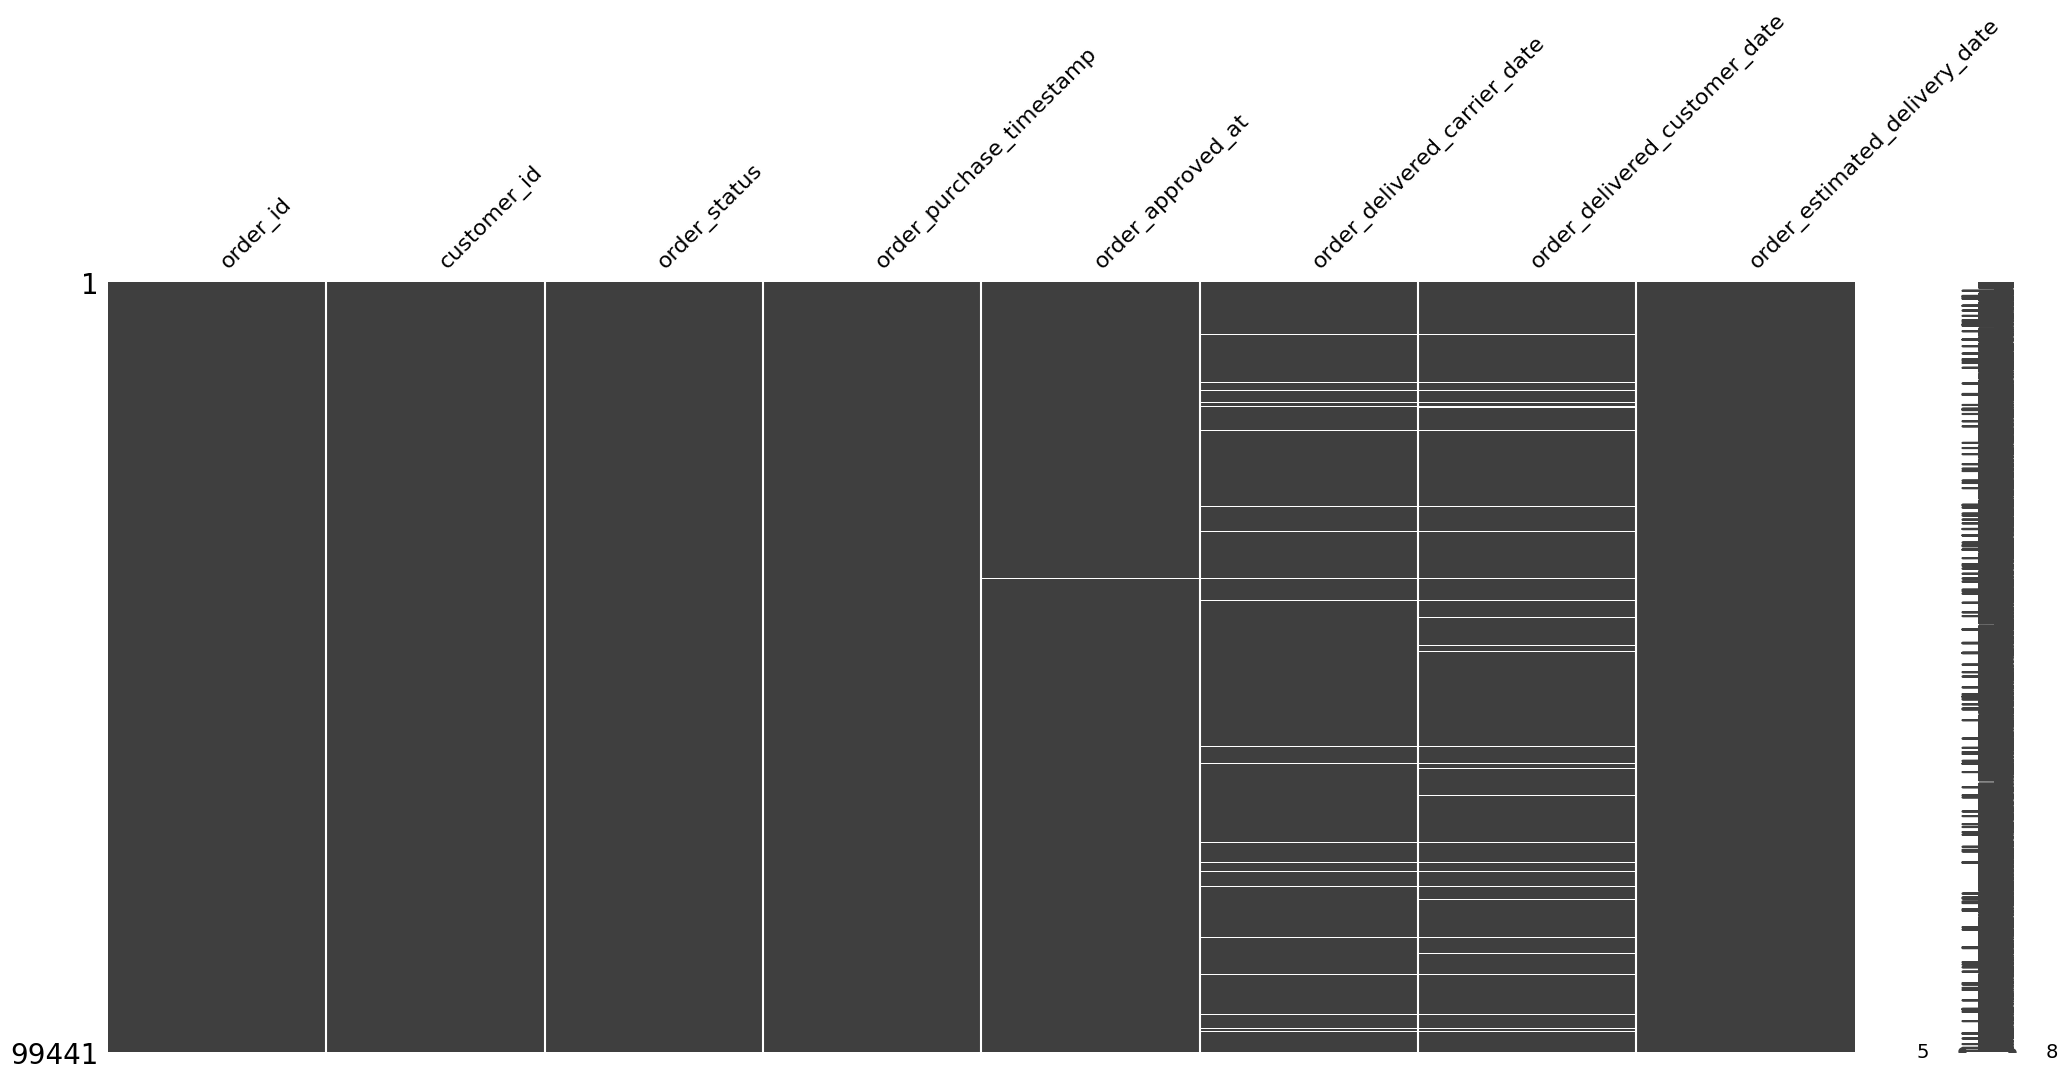

In [8]:
msno.matrix(orders)

plt.show()

# 5.     Duplicate Value Analysis

This section checks whether duplicate records exist in the dataset.


In [9]:
orders.duplicated().sum()

np.int64(0)

# 6. Convert Date Columns

Date columns are converted into datetime format for:
- Time-series analysis
- Cohort analysis
- Delivery analysis


In [10]:
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

orders['order_delivered_customer_date'] = pd.to_datetime(
    orders['order_delivered_customer_date']
)

orders['order_estimated_delivery_date'] = pd.to_datetime(
    orders['order_estimated_delivery_date']
)

# 7. Merge Datasets

The multiple tables are merged together using:
- customer_id
- order_id
- product_id
- seller_id

This creates one master dataset for analysis.


In [11]:
df = orders.merge(
    customers,
    on='customer_id',
    how='left'
)

df = df.merge(
    payments,
    on='order_id',
    how='left'
)

df = df.merge(
    reviews,
    on='order_id',
    how='left'
)

df = df.merge(
    items,
    on='order_id',
    how='left'
)

df = df.merge(
    products,
    on='product_id',
    how='left'
)

df = df.merge(
    sellers,
    on='seller_id',
    how='left'
)

In [12]:
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,payment_sequential,payment_type,payment_installments,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,seller_zip_code_prefix,seller_city,seller_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,credit_card,1.0,18.12,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,9350.0,maua,SP
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,3.0,voucher,1.0,2.00,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,9350.0,maua,SP
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,2.0,voucher,1.0,18.59,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,9350.0,maua,SP
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,boleto,1.0,141.46,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,31570.0,belo horizonte,SP
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,credit_card,3.0,179.12,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,14840.0,guariba,SP


# 8. Feature Engineering

New columns are created to support:
- Revenue analysis
- Delivery analysis
- Time-series analysis


In [13]:
df['total_price'] = (
    df['price'] + df['freight_value']
)

df['delivery_delay'] = (
    df['order_delivered_customer_date']
    - df['order_estimated_delivery_date']
).dt.days

df['purchase_month'] = (
    df['order_purchase_timestamp']
    .dt.to_period('M')
)

# 9. KPI Analysis

This section calculates important business KPIs:
- Total Revenue
- Average Order Value
- Customer Satisfaction


In [14]:
# Total revenue calculated per unique order to avoid duplicate counting across multi-item orders
order_revenue = df.groupby('order_id')['payment_value'].first()
total_revenue = order_revenue.sum()

print(f'Total Revenue: R$ {total_revenue:,.2f}')


20579664.01


In [15]:
# Average Order Value (AOV)
aov = order_revenue.mean()

print(f'Average Order Value (AOV): R$ {aov:,.2f}')


206.9535102221418


In [16]:
avg_review = df['review_score'].mean()

print(avg_review)

4.015582414978078


In [17]:
repeat_customers = df.groupby(
    'customer_unique_id'
)['order_id'].nunique()

retention_rate = (
    (repeat_customers > 1).sum()
    / repeat_customers.count()
) * 100

print(retention_rate)

3.1187562437562435


# 10. Revenue Analysis

This section analyzes:
- Monthly revenue trends
- Product category performance
- State-wise sales performance


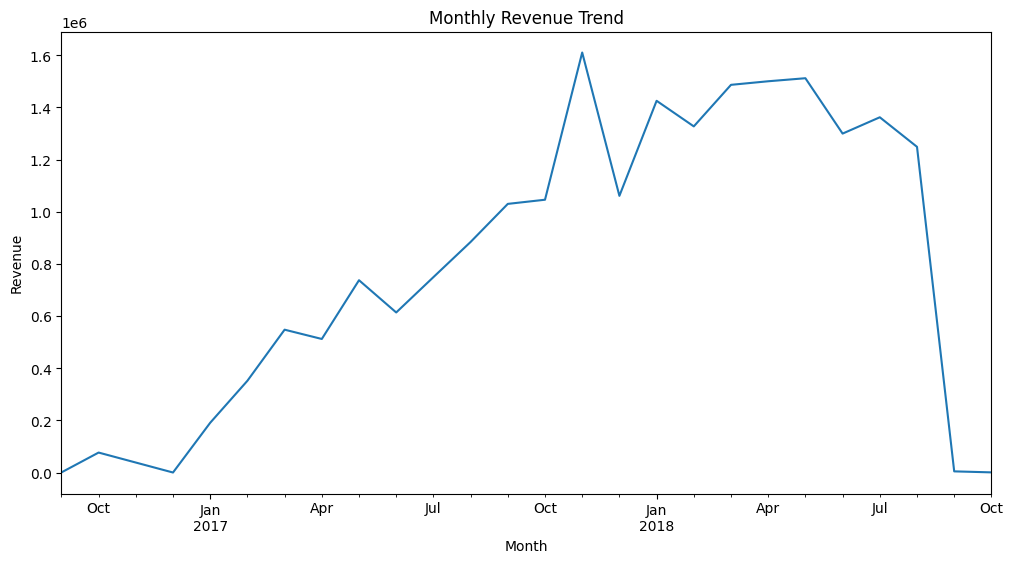

In [18]:
monthly_revenue = df.groupby(
    df['order_purchase_timestamp'].dt.to_period('M')
)['payment_value'].sum()

monthly_revenue.plot(figsize=(12,6))

plt.title("Monthly Revenue Trend")

plt.xlabel("Month")

plt.ylabel("Revenue")

plt.show()

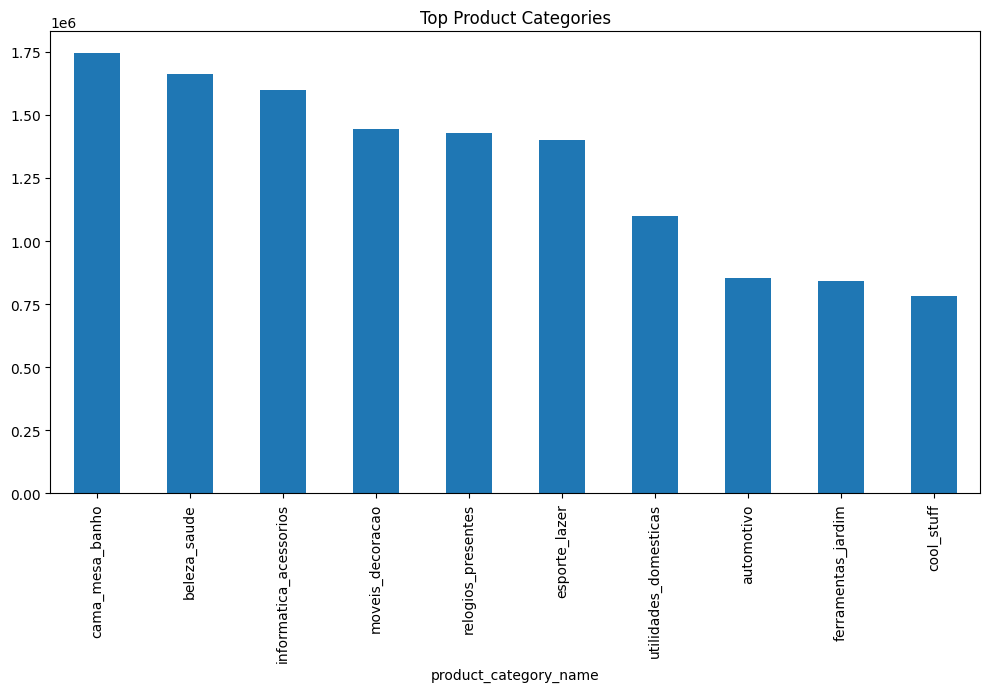

In [19]:
top_categories = df.groupby(
    'product_category_name'
)['payment_value'].sum().sort_values(
    ascending=False
).head(10)

top_categories.plot(
    kind='bar',
    figsize=(12,6)
)

plt.title("Top Product Categories")

plt.show()

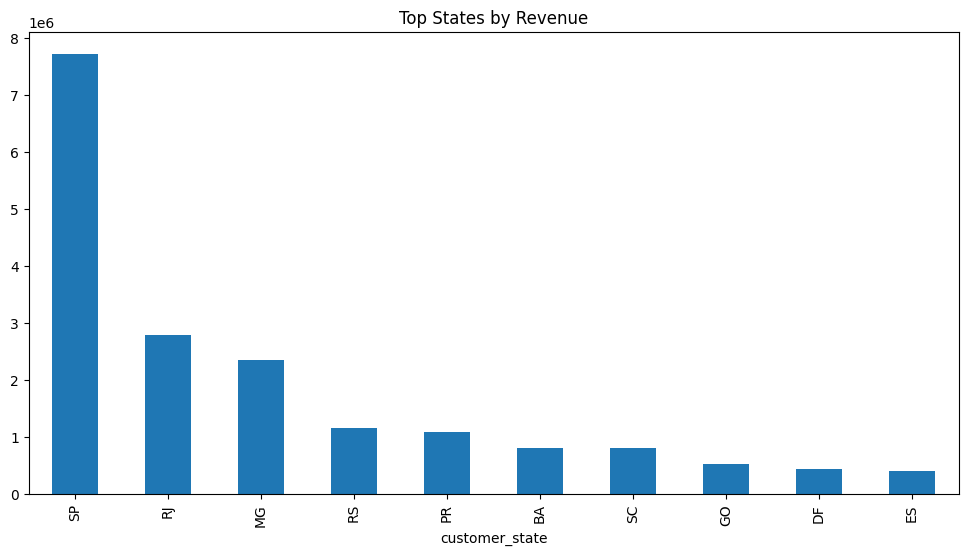

In [20]:
state_revenue = df.groupby(
    'customer_state'
)['payment_value'].sum().sort_values(
    ascending=False
).head(10)

state_revenue.plot(
    kind='bar',
    figsize=(12,6)
)

plt.title("Top States by Revenue")

plt.show()

# 11. Delivery Performance Analysis

This section evaluates:
- Delivery delays
- Delivery time
- Operational efficiency


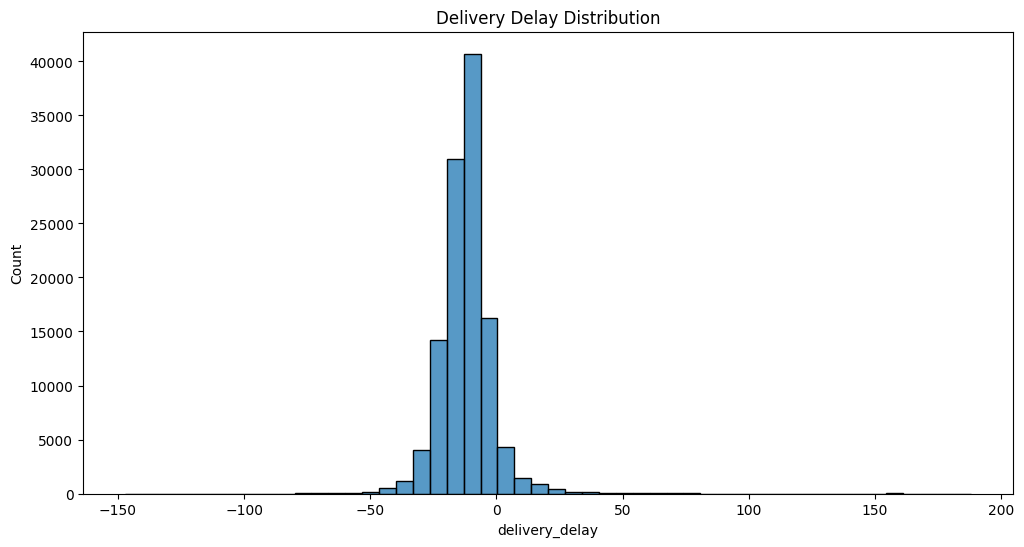

In [21]:
plt.figure(figsize=(12,6))

sns.histplot(
    df['delivery_delay'],
    bins=50
)

plt.title("Delivery Delay Distribution")

plt.show()

In [22]:
late_orders = df[df['delivery_delay'] > 0]

late_percentage = (
    len(late_orders) / len(df)
) * 100

print(late_percentage)

6.344476805183687


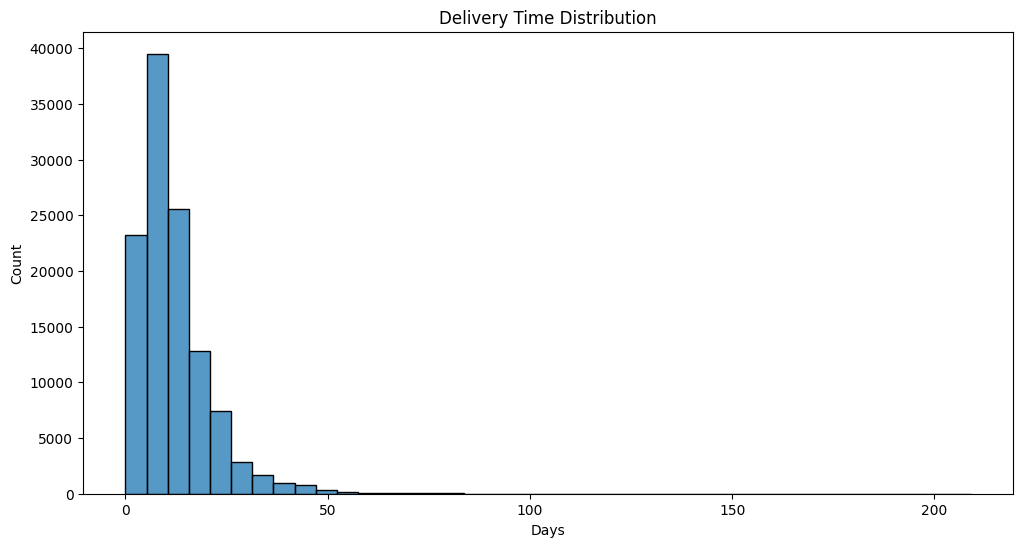

In [23]:
df['order_purchase_timestamp'] = pd.to_datetime(
    df['order_purchase_timestamp'],
    errors='coerce'
)

df['order_delivered_customer_date'] = pd.to_datetime(
    df['order_delivered_customer_date'],
    errors='coerce'
)

df['delivery_time'] = (
    df['order_delivered_customer_date']
    - df['order_purchase_timestamp']
).dt.days

df['delivery_time'] = pd.to_numeric(
    df['delivery_time'],
    errors='coerce'
)

plt.figure(figsize=(12,6))

sns.histplot(
    df['delivery_time'].dropna(),
    bins=40
)

plt.title("Delivery Time Distribution")

plt.xlabel("Days")

plt.ylabel("Count")

plt.show()

# 12. Customer Review Analysis

This section studies:
- Review score distribution
- Relationship between delivery delays and ratings


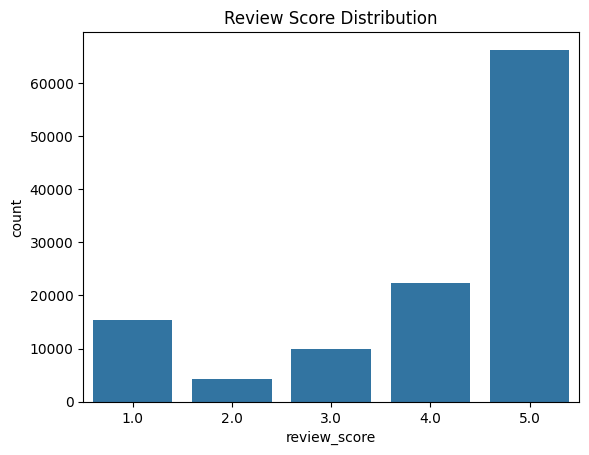

In [24]:
sns.countplot(
    x='review_score',
    data=df
)

plt.title("Review Score Distribution")

plt.show()

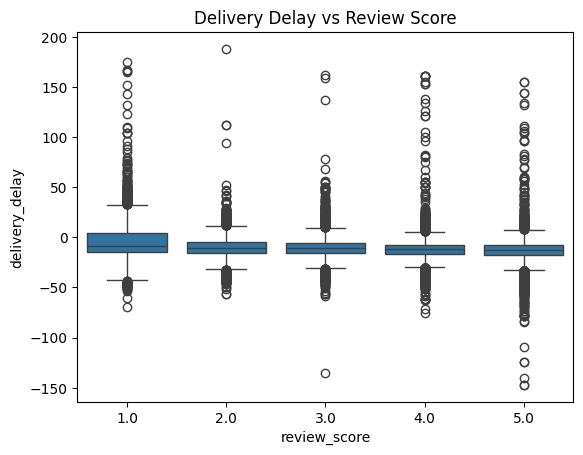

In [25]:
sns.boxplot(
    x='review_score',
    y='delivery_delay',
    data=df
)

plt.title("Delivery Delay vs Review Score")

plt.show()

# 13. Outlier Analysis

Outlier analysis helps identify unusual values that may affect business insights.


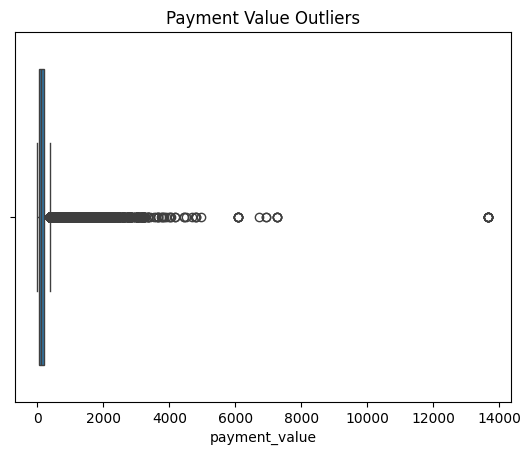

In [26]:
sns.boxplot(
    x=df['payment_value']
)

plt.title("Payment Value Outliers")

plt.show()

# 14. Correlation Analysis

Correlation analysis helps identify relationships between numerical variables.


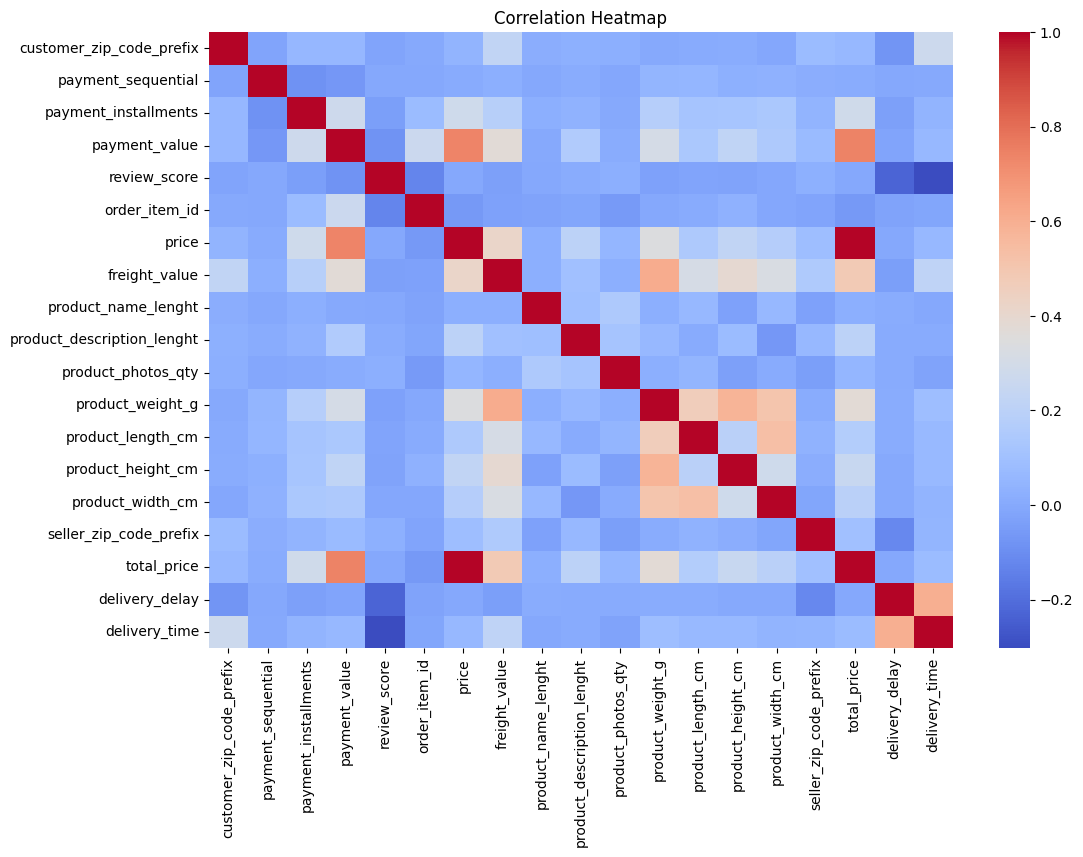

In [27]:
numeric_df = df.select_dtypes(
    include=np.number
)

corr = numeric_df.corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

# 15. Customer Segmentation (RFM Analysis)

RFM analysis segments customers using:
- Recency
- Frequency
- Monetary value


In [28]:
snapshot_date = df[
    'order_purchase_timestamp'
].max()

rfm = df.groupby(
    'customer_unique_id'
).agg({

    'order_purchase_timestamp':
    lambda x:
    (snapshot_date - x.max()).days,

    'order_id': 'nunique',

    'payment_value': 'sum'

})

In [29]:
rfm.columns = [
    'Recency',
    'Frequency',
    'Monetary'
]

rfm.head()

,Recency,Frequency,Monetary
customer_unique_id,,,
0000366f3b9a7992bf8c76cfdf3221e2,160,1,141.90
0000b849f77a49e4a4ce2b2a4ca5be3f,163,1,27.19
0000f46a3911fa3c0805444483337064,585,1,86.22
0000f6ccb0745a6a4b88665a16c9f078,369,1,43.62
0004aac84e0df4da2b147fca70cf8255,336,1,196.89


# 16. Cohort Analysis

Cohort analysis measures customer retention behavior over time.


In [30]:
df['PurchaseMonth'] = (
    df['order_purchase_timestamp']
    .dt.to_period('M')
)

df['CohortMonth'] = df.groupby(
    'customer_unique_id'
)['PurchaseMonth'].transform('min')

# 17. Funnel Analysis

This section analyzes the order lifecycle stages.


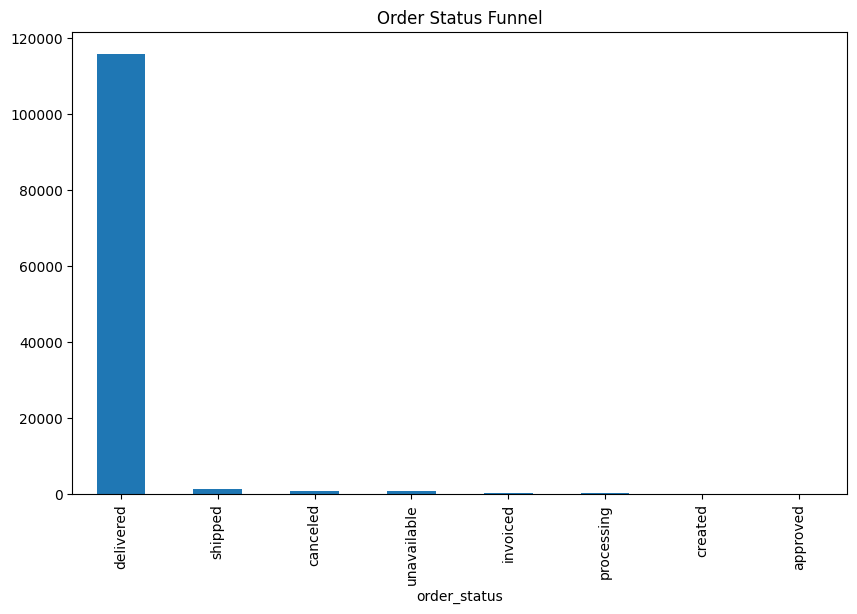

In [31]:
funnel = df['order_status'].value_counts()

funnel.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title("Order Status Funnel")

plt.show()

# 18. Machine Learning: Customer Satisfaction Prediction

In this section, we build a **Decision Tree Classifier** to predict whether a customer will leave a high satisfaction review (score >= 4) based on fulfillment and order characteristics:
- `price`
- `freight_value`
- `delivery_delay` (actual delivery - estimated delivery in days)
- `payment_installments`


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Define target: 1 if review_score >= 4 (Satisfied), 0 otherwise
df['is_satisfied'] = (df['review_score'] >= 4).astype(int)

# Prepare feature matrix
features = ['price', 'freight_value', 'delivery_delay', 'payment_installments']
ml_data = df[features + ['is_satisfied']].dropna()

X = ml_data[features]
y = ml_data['is_satisfied']

# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train Decision Tree Classifier
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)

# Predictions & Evaluation
y_pred = dt_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f'Model Accuracy: {acc * 100:.2f}%\n')
print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['Unsatisfied (<4)', 'Satisfied (>=4)']))


In [ ]:
# Feature Importance
feature_importance = pd.Series(dt_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=feature_importance.values, y=feature_importance.index, palette='viridis')
plt.title('Feature Importance for Customer Satisfaction')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Unsatisfied', 'Satisfied'], 
            yticklabels=['Unsatisfied', 'Satisfied'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


# 18. Business Insights

## Major Findings

- Late deliveries negatively impact customer satisfaction.
- A small group of customers contribute significantly to revenue.
- Some product categories dominate overall sales.
- Delivery performance varies across regions.


# 19. Business Recommendations

## Recommendations

- Improve logistics efficiency in high-delay regions.
- Focus on customer retention strategies.
- Improve low-rated product categories.
- Monitor seller performance closely.


# 20. Export Final Dataset

The cleaned and processed dataset is exported for:
- Business intelligence reporting
- Advanced analytics and downstream modeling


In [32]:
df.to_csv(
    "..\\data\\final_olist_dashboard.csv",
    index=False
)

# Conclusion

This project successfully analyzed customer behavior, delivery performance, revenue trends, and satisfaction prediction using the Olist E-Commerce dataset.

Key findings:
- Delivery delays negatively affect customer satisfaction more than price or shipping costs.
- Revenue is concentrated among a subset of customers and product categories.
- Targeted retention initiatives can significantly enhance customer lifetime value.

The processed dataset and predictive models are ready for reporting and production analytics workflows.
